# Exploración de datos para P2 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P2 (clasificación)
**Autor:** Roberto Robles · **Rama:** `feature/p2-riesgo-estaciones`

**Propósito.** Conocer los datos de viajes y de estaciones de MiBici antes de definir la etiqueta de P2. Cada sección responde una pregunta concreta, y las decisiones (tamaño del bloque de tiempo, horizonte, umbral de capacidad, ventanas de entrenamiento) se toman solo con la evidencia que obtengamos en este análisis exploratorio de datos.

**Fuente.** MiBici, portal de Datos abiertos (https://mibici.net/es/datos-abiertos/): 142 archivos mensuales de viajes (diciembre de 2014 a septiembre de 2026) y la nomenclatura de estaciones de septiembre de 2026. Los archivos están en `data/raw/` y no se versionan en Git.

**Datos personales.** Las columnas de usuario, género y año de nacimiento no se usan en P2 ni se muestran a nivel de registro para preservar la privacidad de la información.

In [1]:
# Objetivo: preparar el entorno del notebook.
# Carga las librerías y toma la ruta de los datos desde config.py (configuración en un solo lugar).
# Resultado esperado: la ruta de la carpeta data/raw.

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # raíz del proyecto, para importar el módulo
from equipo52_module.config import RAW_DATA_DIR

pd.set_option("display.max_colwidth", 120)
RAW_DATA_DIR

2026-10-13 17:08:38.615 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: /Users/Roberto/Proyectos/equipo52_proyecto_mibici


PosixPath('/Users/Roberto/Proyectos/equipo52_proyecto_mibici/data/raw')

## 1. Inventario de archivos

Verificación de la estructura de los 142 archivos.

Para cada archivo se revisa: codificación de caracteres, si los valores vienen entre comillas, nombres y número de columnas, tamaño y número de registros. Esto indica qué debe normalizar la ingesta (`dataset.py`) y da el tamaño real de los datos que pide la propuesta.

In [2]:
# Objetivo: construir la tabla del inventario, con una fila por archivo mensual.
# Para cada archivo registra lo que se observa, sin corregir nada: si el encabezado se lee como UTF-8,
# si usa comillas, número de columnas, nombres de columnas, tamaño y número de registros.
# Resultado esperado: ninguno visible; la tabla queda en la variable `inventario` para la celda siguiente.

def leer_primera_linea(ruta):
    """Devuelve la primera línea del archivo tal como está guardada (bytes), sin interpretarla."""
    with ruta.open("rb") as archivo:
        return archivo.readline().rstrip(b"\r\n")


def se_lee_como_utf8(contenido):
    """Indica si los bytes se pueden leer como texto UTF-8, el estándar más común."""
    try:
        contenido.decode("utf-8")
        return True
    except UnicodeDecodeError:
        return False


def contar_registros(ruta):
    """Cuenta las líneas del archivo sin cargarlo en memoria (descuenta el encabezado)."""
    with ruta.open("rb") as archivo:
        bloques = iter(lambda: archivo.read(1 << 20), b"")
        return sum(bloque.count(b"\n") for bloque in bloques) - 1


def describir_archivo(ruta):
    """Reúne en un diccionario lo que se observa en un archivo mensual, sin corregir nada."""
    encabezado = leer_primera_linea(ruta)
    anio, mes = ruta.stem.split("_")[2:4]
    return {
        "archivo": ruta.name,
        "anio": int(anio),
        "mes": int(mes[:2]),
        "tamano_mb": round(ruta.stat().st_size / 1e6, 1),
        "encabezado_utf8": se_lee_como_utf8(encabezado),
        "entre_comillas": encabezado.startswith(b'"'),
        "num_columnas": encabezado.count(b",") + 1,
        # Los bytes que no son UTF-8 se muestran tal cual (p. ej. \xf1), sin adivinar la letra
        "encabezado": encabezado.decode("utf-8", errors="backslashreplace").replace('"', ""),
        "registros": contar_registros(ruta),
    }


archivos_viajes = sorted(RAW_DATA_DIR.glob("datos_abiertos_*.csv"))
inventario = (
    pd.DataFrame([describir_archivo(ruta) for ruta in archivos_viajes])
    .sort_values(["anio", "mes"], ignore_index=True)
)
print(f"Archivos revisados: {len(inventario)}")

Archivos revisados: 142


In [3]:
# Objetivo: responder si los 142 archivos tienen la misma estructura.
# Resultado esperado: total de archivos, periodo, registros y tamaño; cuántos archivos hay de cada formato
# (UTF-8 o no, con o sin comillas) y cuántas versiones distintas del encabezado existen.

print(f"Archivos: {len(inventario)}")
print(f"Periodo: {inventario.anio.iloc[0]}-{inventario.mes.iloc[0]:02d} a "
      f"{inventario.anio.iloc[-1]}-{inventario.mes.iloc[-1]:02d}")
print(f"Registros totales: {inventario.registros.sum():,}")
print(f"Tamaño total: {inventario.tamano_mb.sum():,.0f} MB\n")

print("¿El encabezado se lee como UTF-8? ¿Viene entre comillas?")
display(inventario.groupby(["encabezado_utf8", "entre_comillas"]).size().rename("archivos").to_frame())

print("Variantes de encabezado:")
display(inventario.groupby("encabezado").agg(
    archivos=("archivo", "count"),
    ejemplos=("archivo", lambda s: ", ".join(s.head(4))),
))

Archivos: 142
Periodo: 2014-12 a 2026-09
Registros totales: 39,078,840
Tamaño total: 3,107 MB

¿El encabezado se lee como UTF-8? ¿Viene entre comillas?


archivos
encabezado_utf8 entre_comillas          
False           False                  3
                True                  42
True            False                 78
                True                  19

Variantes de encabezado:


,archivos,ejemplos
encabezado,,
"Viaje_Id,Usuario_Id,Genero,A\xf1o_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id",41,"datos_abiertos_2021_06.csv, datos_abiertos_2021_07.csv, datos_abiertos_2021_08.csv, datos_abiertos_2021_09.csv"
"Viaje_Id,Usuario_Id,Genero,A}\xe4e_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id",4,"datos_abiertos_2023_04.csv, datos_abiertos_2023_05.csv, datos_abiertos_2024_02.csv, datos_abiertos_2024_05.csv"
"Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id",97,"datos_abiertos_2014_12.csv, datos_abiertos_2015_01.csv, datos_abiertos_2015_02.csv, datos_abiertos_2015_03.csv"


In [4]:
# Objetivo: ver cómo luce un registro real de cada formato encontrado en la celda 5.
# Se muestran solo las columnas que no identifican ni describen a las personas usuarias:
# viaje, inicio, fin, estación de origen y de destino.
# Resultado esperado: una fila por formato, para comparar comillas, fechas y números entre formatos.

def leer_segunda_linea(ruta):
    """Devuelve el primer registro de datos del archivo, tal como está guardado."""
    with ruta.open("rb") as archivo:
        archivo.readline()
        return archivo.readline().rstrip(b"\r\n")


COLUMNAS_NO_PERSONALES = [0, 4, 5, 6, 7]  # viaje, inicio, fin, origen, destino

ejemplos = []
for (utf8, comillas), grupo in inventario.groupby(["encabezado_utf8", "entre_comillas"]):
    ruta = RAW_DATA_DIR / grupo.archivo.iloc[0]
    campos = leer_segunda_linea(ruta).decode("utf-8", errors="backslashreplace").split(",")
    ejemplos.append({
        "encabezado_utf8": utf8,
        "entre_comillas": comillas,
        "archivo_ejemplo": ruta.name,
        "registro (sin datos personales)": ",".join(campos[i] for i in COLUMNAS_NO_PERSONALES),
    })

pd.DataFrame(ejemplos)

,encabezado_utf8,entre_comillas,archivo_ejemplo,registro (sin datos personales)
0,False,False,datos_abiertos_2023_11.csv,"30965755,01/11/2023 0:01,01/11/2023 0:29,39,85"
1,False,True,datos_abiertos_2021_06.csv,"""19405303"",""2021-06-01 00:00:40"",""2021-06-01 00:05:28"",""140"",""225"""
2,True,False,datos_abiertos_2014_12.csv,"4601,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47"
3,True,True,datos_abiertos_2022_12.csv,"""26361352"",""2022-12-01 00:00:09"",""2022-12-01 00:04:23"",""65"",""43"""


In [5]:
# Objetivo: saber qué formatos de fecha existen y en qué archivos aparece cada uno.
# Se toma la fecha de inicio del primer registro de cada archivo y se reemplaza cada dígito por "9",
# para comparar solo la forma (p. ej. 2014-12-01 00:33:47 → 9999-99-99 99:99:99).
# Resultado esperado: cada patrón de fecha encontrado, con cuántos archivos lo usan y cuáles.

import re


def patron_de_fecha(texto):
    """Reemplaza cada dígito por 9 para comparar solo la forma de la fecha."""
    return re.sub(r"\d", "9", texto)


def fecha_inicio_primer_registro(ruta):
    """Devuelve el texto de la fecha de inicio (columna 5) del primer registro."""
    campos = leer_segunda_linea(ruta).decode("utf-8", errors="backslashreplace").replace('"', "").split(",")
    return campos[4]


inventario["patron_fecha"] = [
    patron_de_fecha(fecha_inicio_primer_registro(RAW_DATA_DIR / archivo))
    for archivo in inventario.archivo
]
inventario.groupby("patron_fecha").agg(
    archivos=("archivo", "count"),
    cuales=("archivo", lambda s: ", ".join(s.str[15:22])),
)

,archivos,cuales
patron_fecha,,
99/99/9999 9:99,3,"2023_11, 2024_09, 2024_10"
9999-99-99 99:99:99,139,"2014_12, 2015_01, 2015_02, 2015_03, 2015_04, 2015_05, 2015_06, 2015_07, 2015_08, 2015_09, 2015_10, 2015_11, 2015_12,..."


### Conclusiones del inventario de archivos

- **Volumen:** 142 archivos mensuales (diciembre de 2014 a septiembre de 2026), 39,078,840 registros y 3,107 MB.
- **Columnas:** todos los archivos tienen 8 columnas en el mismo orden. Siete nombres son idénticos en todos; el cuarto (año de nacimiento) aparece en tres versiones:
  - `Año_de_nacimiento` en 97 archivos, legible como UTF-8.
  - `A\xf1o_de_nacimiento` en 41 archivos: el byte `\xf1` ocupa el lugar de la «ñ», lo que indica otra codificación de caracteres.
  - `A}\xe4e_nacimiento` en 4 archivos (2023-04, 2023-05, 2024-02 y 2024-05): encabezado dañado.
- **Comillas:** 61 archivos encierran los valores entre comillas y 81 no.
- **Fechas:** 139 archivos usan el formato `AAAA-MM-DD HH:MM:SS`; 3 (2023-11, 2024-09 y 2024-10) usan `DD/MM/AAAA H:MM`, sin segundos. En el archivo de noviembre de 2023 el registro de ejemplo dice `01/11/2023`, lo que indica que el primer número es el día.

**Implicaciones para la ingesta (`dataset.py`):**
1. Asignar los nombres de columna por posición, sin depender del encabezado de cada archivo.
2. Leer cada archivo con la codificación que corresponda, sin suponer una sola para todos.
3. Interpretar los dos formatos de fecha, indicando que el día va primero en el formato con diagonales.
4. Para estas decisiones, la evidencia es esta sección; la corrección se hace en la ingesta, no en este notebook.

## 2. Tendencias de viajes, diciembre de 2014 a septiembre de 2026

Uso de MiBici a lo largo del tiempo y qué pasó durante la emergencia sanitaria de COVID-19

Esta sección es la evidencia para definir las dos ventanas de entrenamiento que se compararán (completa o Post-Covid). Se marcan como referencia las fechas oficiales de la emergencia sanitaria: inicio el 23 de marzo de 2020 y término el 9 de mayo de 2023 (decreto publicado en el DOF).

*Nota:* aquí cada registro se cuenta como un viaje; en una sección posterior se verificará al leer los datos completos (registros vacíos o duplicados).

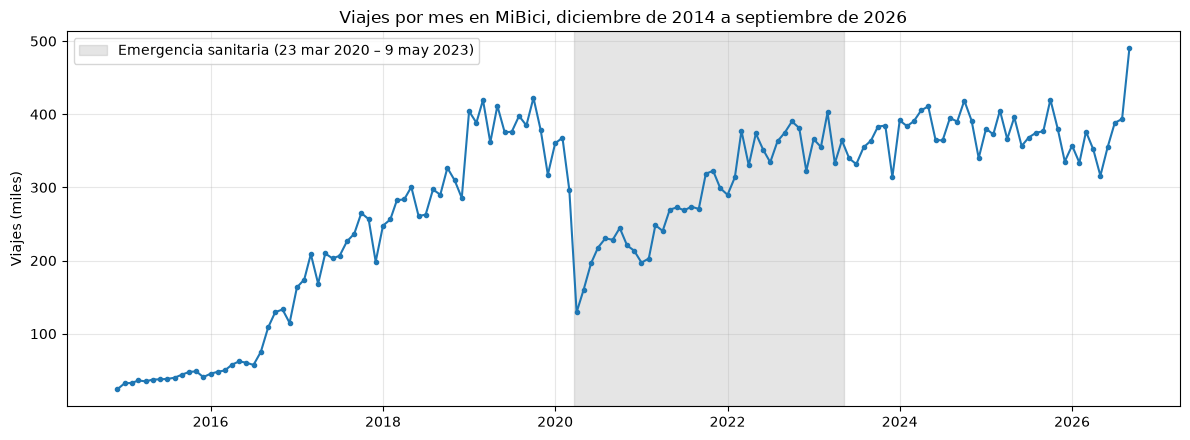

,meses,viajes,promedio_mensual
mes_inicio,,,
2014,1,23967,23967
2015,12,469871,39156
2016,12,941918,78493
2017,12,2516534,209711
2018,12,3403485,283624
2019,12,4636652,386388
2020,12,2866072,238839
2021,12,3184410,265368
2022,12,4202942,350245


In [6]:
# Objetivo: ver la evolución de los viajes mensuales y el efecto de la emergencia sanitaria.
# Usa los registros por archivo calculados en el inventario (cada archivo es un mes).
# Resultado esperado: una gráfica de viajes por mes con el periodo de emergencia sombreado,
# guardada en reports/figures/, y una tabla con viajes por año.

import matplotlib.pyplot as plt
from equipo52_module.config import FIGURES_DIR

INICIO_EMERGENCIA = pd.Timestamp("2020-03-23")
FIN_EMERGENCIA = pd.Timestamp("2023-05-09")  # decreto DOF 9 may 2023

viajes_por_mes = (
    inventario
    .assign(mes_inicio=pd.to_datetime(dict(year=inventario.anio, month=inventario.mes, day=1)))
    .set_index("mes_inicio")["registros"]
)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(viajes_por_mes.index, viajes_por_mes.values / 1000, marker="o", markersize=3)
ax.axvspan(INICIO_EMERGENCIA, FIN_EMERGENCIA, color="grey", alpha=0.2,
           label="Emergencia sanitaria (23 mar 2020 – 9 may 2023)")
ax.set_title("Viajes por mes en MiBici, diciembre de 2014 a septiembre de 2026")
ax.set_ylabel("Viajes (miles)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "p2_viajes_por_mes.png", dpi=150)
plt.show()

viajes_por_mes.groupby(viajes_por_mes.index.year).agg(
    meses="count", viajes="sum", promedio_mensual="mean"
).round(0).astype(int)

In [7]:
# Objetivo: medir el crecimiento del sistema en su etapa de expansión, tomando 2015 como línea base (0 %).
# Se excluye 2014 porque solo contiene diciembre: compararlo con años de 12 meses inflaría el crecimiento.
# Resultado esperado: viajes por año de 2015 a 2019 y crecimiento porcentual acumulado frente a 2015.

viajes_por_anio = viajes_por_mes.groupby(viajes_por_mes.index.year).agg(meses="count", viajes="sum", promedio_mensual="mean")

expansion = viajes_por_anio.loc[2015:2019, ["viajes"]].copy()
expansion["crecimiento_vs_2015_%"] = ((expansion.viajes / expansion.loc[2015, "viajes"] - 1) * 100).round(0)
expansion

,viajes,crecimiento_vs_2015_%
mes_inicio,,
2015,469871,0.0
2016,941918,100.0
2017,2516534,436.0
2018,3403485,624.0
2019,4636652,887.0


In [8]:
# Objetivo: medir cuánto disminuyeron los viajes durante la emergencia sanitaria y cuándo se recuperaron.
# Compara los viajes de cada año contra 2019, el último año previo a la pandemia.
# Se muestran los años completos de 2019 a 2025; 2026 se excluye porque solo tiene 9 meses.
# Resultado esperado: viajes anuales y variación porcentual contra 2019 (se usa en la conclusión de esta sección).

referencia_2019 = viajes_por_anio.loc[2019, "promedio_mensual"]
viajes_por_anio["variacion_vs_2019_%"] = ((viajes_por_anio.promedio_mensual / referencia_2019 - 1) * 100).round(1)
viajes_por_anio.loc[2019:2025, ["viajes", "variacion_vs_2019_%"]]

,viajes,variacion_vs_2019_%
mes_inicio,,
2019,4636652,0.0
2020,2866072,-38.2
2021,3184410,-31.3
2022,4202942,-9.4
2023,4292971,-7.4
2024,4645921,0.2
2025,4532032,-2.3


In [9]:
# Objetivo: incluir 2026 en la comparación, aunque solo tenga 9 meses de datos.
# Para comparar lo mismo con lo mismo, se suman solo los meses de enero a septiembre de cada año.
# Resultado esperado: viajes de enero a septiembre de 2019 a 2026, con su variación contra 2019 y contra 2025.

ene_sep = viajes_por_mes[viajes_por_mes.index.month <= 9]
viajes_ene_sep = ene_sep.groupby(ene_sep.index.year).sum().loc[2019:2026].rename("viajes_ene_sep").to_frame()
viajes_ene_sep["variacion_vs_2019_%"] = ((viajes_ene_sep.viajes_ene_sep / viajes_ene_sep.loc[2019, "viajes_ene_sep"] - 1) * 100).round(1)
viajes_ene_sep["variacion_vs_2025_%"] = ((viajes_ene_sep.viajes_ene_sep / viajes_ene_sep.loc[2025, "viajes_ene_sep"] - 1) * 100).round(1)
viajes_ene_sep

,viajes_ene_sep,variacion_vs_2019_%,variacion_vs_2025_%
mes_inicio,,,
2019,3518892,0.0,3.6
2020,2187323,-37.8,-35.6
2021,2243970,-36.2,-33.9
2022,3109042,-11.6,-8.5
2023,3211104,-8.7,-5.5
2024,3496093,-0.6,2.9
2025,3396220,-3.5,0.0
2026,3362065,-4.5,-1.0


### Conclusiones de las tendencias de viaje

- **Expansión del sistema:** tomando 2015 como línea base (469,871 viajes), los viajes anuales crecieron 100 % en 2016, 436 % en 2017, 624 % en 2018 y 887 % en 2019 (4,636,652 viajes). Se usa 2015 como base porque es el primer año completo; 2014 se excluye porque solo contiene diciembre, el primer mes con datos publicados.
- **Emergencia sanitaria:** frente a 2019, los viajes anuales disminuyeron 38 % en 2020, 31 % en 2021, 9 % en 2022 y 7 % en 2023.
- **Recuperación:** en 2024 se alcanzó el nivel de 2019 (4,645,921 viajes) y en 2025 se mantuvo cercano (−2 %).
- **2026 (enero a septiembre):** 3,362,065 viajes, 1.0 % menos que el mismo periodo de 2025 y 4.5 % menos que el de 2019; con los datos disponibles no se observa un crecimiento en 2026.

**Implicaciones para las ventanas de entrenamiento:**
1. La historia completa (diciembre de 2014 a septiembre de 2026) mezcla tres etapas distintas: expansión, emergencia sanitaria y recuperación.
2. La ventana Post-Covid (desde el 9 de mayo de 2023) coincide con los años más cercanos al nivel de 2019: 2023 (−7 %), 2024 (0 %) y 2025 (−2 %).
3. Se entrenarán ambas ventanas y se compararán con el mismo periodo de evaluación, para medir con evidencia cuánto afecta incluir las etapas anteriores.
4. El periodo de evaluación (abril a septiembre de 2026) tiene un nivel de uso similar a 2025, por lo que es comparable con los años recientes de entrenamiento. Septiembre de 2026 se revisará en la sección de estaciones, porque en la gráfica aparece como el mes más alto de la serie.